# PDNO con simbolos parabolicos: calor 1D

Se aprende el operador solucion $u_0\mapsto u(t)$ del calor en $\mathbb{T}^1$ con la arquitectura PDNO
(Shin et al., 2024, ec. (1)). El nucleo de cada capa lo da un `ParabolicMLPSymbol` par:

$$v_0=P(u_0),\qquad v_{\ell+1}=\sigma\big(W_\ell v_\ell+K_\ell v_\ell+b_\ell\big),\qquad u(t)=Q(v_L),\qquad
K_\ell v=\mathcal F^{-1}\big[e^{-\tau_\ell t\,a_{\text{par}}^{(\ell)}(k)}\,\mathcal F v\big],$$

con $a_{\text{par}}(k)=\tfrac12\big(a_\theta(k)+a_\theta(-k)\big)$, $\tau_\ell\ge0$ y $\sum_\ell\tau_\ell=1$. Aqui se usa la
**configuracion lineal** ($d=1$, sin $W$ ni sesgos, $\sigma=$ identidad, $P=Q=$ identidad): la red es el semigrupo
$u(t)=e^{-t\bar a(D)}u_0$ con $\bar a=\sum_\ell\tau_\ell a_{\text{par}}^{(\ell)}$, que sigue en la banda $(c,C)$.

**Funcion de perdida** (una sola, un solo optimizador)

$$\mathcal L=\mathbb E_b\frac{\|u_\theta(t_b)-u(t_b)\|_{L^2}}{\|u(t_b)\|_{L^2}}
+\lambda_{\text{par}}\sum_\ell\mathcal L_{\text{par}}\big(a_{\text{par}}^{(\ell)}\big)
+\lambda_{\text{class}}\sum_\ell\mathcal L_{\text{class}}\big(a_{\text{par}}^{(\ell)}\big)$$

- **$L^2$ relativa:** en espacio fisico, sobre la salida de la red, por muestra $(u_0,t)$ y promediada.
- **$\mathcal L_{\text{par}}$ (Def. 2.3) y $\mathcal L_{\text{class}}$ (Def. 2.1):** las de `02_calor_1d.ipynb`, evaluadas
  sobre el simbolo de cada capa. Con la banda, $\mathcal L_{\text{par}}$ es practicamente cero por construccion.

Referencia: $a(k)=|k|^2$ (`HeatSymbol`), $n=1$, $m=2$, $\rho=n+1=2$.

# Setup
- **Datos:** los GRF del paper y de `02_calor_1d.ipynb`, en `float64`, como **campos completos** en la malla de
  $1024$ puntos. La particion es **por condicion inicial**: todos los tiempos de una $u_0$ caen en el mismo conjunto.
  La validacion son $u_0$ nuevas en `TRAIN_TIMES` (early stopping); la prueba, las $20$ $u_0$ de prueba en `TEST_TIMES`.
- **$\kappa$, $(c,C)$ y $C_\alpha$:** como en 02, solo con las $u_0$ de entrenamiento (`ds.rows_train`).
- **Entrenamiento:** los valores por defecto de `OperatorTrainingConfig`, con `class_C_source="data"` y $k_{\max}=k_{\text{cap}}$.

La celda de parametros reune todo lo configurable.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.parabolic_mlp_symbol import ParabolicMLPSymbol
from parabolic_symbol.verification.parabolicity import ParabolicityVerifier
from parabolic_symbol.verification.symbol_class import SymbolClassVerifier
from parabolic_symbol.data.fields import field_datasets
from parabolic_symbol.data.grf import TEST_TIMES, TRAIN_TIMES
from parabolic_symbol.data.grids import k_grid
from parabolic_symbol.operators.config import PDNOConfig
from parabolic_symbol.operators.pdno import PDNO, EffectiveSymbol
from parabolic_symbol.learning.estimation import (
    estimate_bounds,
    estimate_class_constants,
    estimate_symbol,
    oracle_class_constants,
    symbol_values,
)
from parabolic_symbol.learning.evaluation import symbol_report
from parabolic_symbol.learning.experiment import CERT_LAM, class_C_table, relative_symbol_error
from parabolic_symbol.learning.operator_evaluation import field_errors
from parabolic_symbol.learning.operator_training import (
    OperatorTrainingConfig,
    load_operator_model,
    save_operator_model,
    train_operator,
)
from parabolic_symbol.utils import default_device

np.set_printoptions(precision=4, suppress=True)

In [2]:
# ---------------------------------------------------------------- parametros
# Precision y device: float64 en todo.
DEVICE = default_device()
DTYPE = torch.float64

# Datos: como en el paper y en 02.
REFERENCE = HeatSymbol(n=1)    # a(k) = |k|^2
M = 2.0                        # orden del simbolo aprendido
RESOLUTION = 1024
K_CAP = 64                     # filas espectrales |k| <= k_cap para (c, C) y C_alpha; k_max = k_cap
SEED = 0                       # 100 u0 de entrenamiento (TRAIN_TIMES) y 20 de prueba (TEST_TIMES)
VAL_FRACTION = 0.2             # fraccion de las u0 de entrenamiento que va a validacion
DELTA = 0.1                    # margen de la banda (c, C)
ESTIMATE_TOL = 1e-10           # filtro de senal de estimate_symbol

# Extrapolacion temporal: apagada. Ejemplo (t en [1, 2], todos > max(TRAIN_TIMES) = 0.95):
# EXTRAPOLATION_TIMES = np.linspace(1.0, 2.0, 11)
EXTRAPOLATION_TIMES = None

# Modelo: configuracion lineal (caso calor / laplaciano fraccionario).
ARCH = dict(width=1, use_W=False, bias=False, activation="identity", lift="identity", project="identity")
N_LAYERS = 1                   # L
LEARN_TAU = False              # tau fijo en 1/L
SYMBOL_HIDDEN = (64, 64, 64)   # MLP g_theta del simbolo: un ancho por capa oculta
MODEL_SEED = 0

# Entrenamiento: valores por defecto de OperatorTrainingConfig, con C_alpha de los datos.
TRAIN_CONFIG = OperatorTrainingConfig(k_max=K_CAP, class_C_source="data")
OMEGA = TRAIN_CONFIG.omega
CLASS_MARGIN = TRAIN_CONFIG.class_margin

RESULTS = Path("../results/06_pdno_calor_1d")   # tablas (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)
print(f"device = {DEVICE}  |  dtype = {DTYPE}")

device = cuda  |  dtype = torch.float64


## 1. Datos

`field_datasets` genera los mismos GRF que 02 y los devuelve como campos $u_0$ de forma `(n_ic, 1024)` y
$u$ de forma `(n_ic, T, 1024)`, con todos los modos de la malla. Cada muestra es un par (condicion inicial, $t$).
Entrenamiento y validacion son indices disjuntos de las mismas $100$ $u_0$; la prueba sale de otro flujo aleatorio,
asi que se compara contra las demas por los propios campos.

In [3]:
ds = field_datasets(
    REFERENCE, RESOLUTION, SEED, k_cap=K_CAP, val_fraction=VAL_FRACTION,
    extrapolation_times=EXTRAPOLATION_TIMES,
)
k_max = K_CAP

conjuntos = {"entrenamiento": ds.train, "validacion": ds.val, "prueba": ds.test}
if ds.extrapolation is not None:
    conjuntos["extrapolacion"] = ds.extrapolation   # las mismas u0 de prueba, en otros tiempos

assert np.allclose(ds.train.t, TRAIN_TIMES) and np.allclose(ds.test.t, TEST_TIMES)

# Disjuntos: entrenamiento / validacion por indice; prueba frente a ambos por distancia entre campos u0.
assert set(ds.train.ic).isdisjoint(ds.val.ic)
vistas = torch.cat([ds.train.u0, ds.val.u0])
distancia = torch.cdist(ds.test.u0, vistas).min() / torch.linalg.vector_norm(ds.test.u0, dim=1).min()
assert distancia > 0

print()
print(f"k_max = k_cap = {k_max}")
for nombre, data in conjuntos.items():
    print(f"{nombre:14s}: {data.n_ic:3d} condiciones iniciales x {data.n_times:2d} tiempos = {data.n_pairs:4d} pares")
print(f"entrenamiento y validacion disjuntos: {set(ds.train.ic).isdisjoint(ds.val.ic)}")
print(f"prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = {float(distancia):.3f}  (> 0: disjunta)")
print(f"filas espectrales para la banda y las C_alpha: {ds.rows_train['k'].shape[0]:,} "
      f"(solo las {ds.train.n_ic} u0 de entrenamiento)")

tabla_datos = pd.DataFrame([
    {"conjunto": nombre, "condiciones_iniciales": data.n_ic, "tiempos": data.n_times,
     "pares": data.n_pairs, "t_min": float(data.t.min()), "t_max": float(data.t.max())}
    for nombre, data in conjuntos.items()
]).set_index("conjunto")
tabla_datos.to_csv(RESULTS / "datos.csv")
display(tabla_datos)

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
entrenamiento y validacion disjuntos: True
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: disjunta)
filas espectrales para la banda y las C_alpha: 103,200 (solo las 80 u0 de entre

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00


**Condiciones iniciales y evolucion.** Dos $u_0$ de entrenamiento y la solucion exacta en algunos tiempos de
`TRAIN_TIMES`, de oscuro a claro con $t$ creciente.

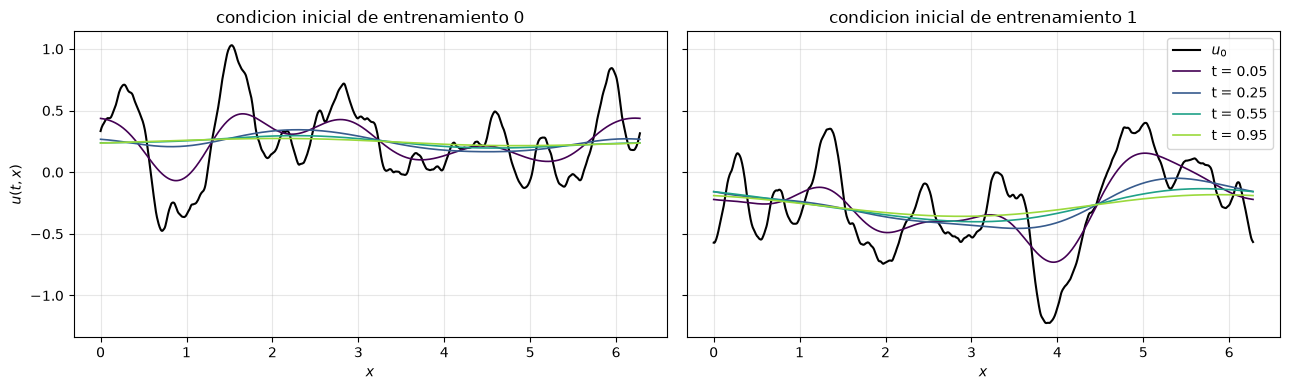

In [4]:
x = 2 * np.pi * np.arange(RESOLUTION) / RESOLUTION
idx_t = [0, 2, 5, 9]                                   # t = 0.05, 0.25, 0.55, 0.95
colores = plt.cm.viridis(np.linspace(0, 0.85, len(idx_t)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, i in zip(axes, (0, 1)):
    ax.plot(x, ds.train.u0[i].numpy(), "k-", lw=1.5, label=r"$u_0$")
    for j, color in zip(idx_t, colores):
        ax.plot(x, ds.train.u[i, j].numpy(), color=color, lw=1.2, label=f"t = {float(ds.train.t[j]):.2f}")
    ax.set_xlabel(r"$x$")
    ax.set_title(f"condicion inicial de entrenamiento {ds.train.ic[i]}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$u(t, x)$")
axes[1].legend()
plt.tight_layout()
fig.savefig(RESULTS / "condiciones_iniciales.png", dpi=150)
plt.show()

## 2. Banda $(c,C)$, $\kappa$ y constantes $C_\alpha$

Como en 02, pero sobre `ds.rows_train`: las filas espectrales $(k,t,\hat u_0,\hat u)$ con $|k|\le k_{\text{cap}}$ de
las $u_0$ de **entrenamiento** (la validacion no entra). `estimate_symbol` ajusta $\hat a(k)$, `estimate_bounds` da
$(c,C)$ con $\delta=0.1$ y $\kappa=$ `theoretical_kappa()`. Las $C_\alpha$ salen del mismo $\hat a$ con margen $1.5$; son
las mismas que calcula `train_operator` con `class_C_source="data"`. Las del oraculo son solo comparacion.

In [5]:
k_est, a_hat = estimate_symbol(ds.rows_train, tol=ESTIMATE_TOL)
bounds = estimate_bounds(k_est, a_hat, m=M, delta=DELTA)
probe = ParabolicMLPSymbol(n=1, m=M, c=bounds.c, C=bounds.C, device="cpu", dtype=DTYPE)
kappa = probe.theoretical_kappa(OMEGA)

class_C, class_C_counts = estimate_class_constants(
    k_est, a_hat, M, rho=probe.rho, margin=CLASS_MARGIN, return_counts=True
)
class_C_oracle = oracle_class_constants(REFERENCE, k_max, margin=CLASS_MARGIN, rho=probe.rho)

print(f"(c, C) de los datos = ({bounds.c:.4f}, {bounds.C:.4f})   m = {M:g}, ventana: {bounds.window}")
print(f"kappa teorico       = {kappa:.4f}   (omega = {OMEGA:g})")

pd.Series({"c": bounds.c, "C": bounds.C, "m": M, "kappa_teorico": kappa},
          name="valor").to_csv(RESULTS / "constantes.csv")
tabla_C = class_C_table(class_C, class_C_oracle, class_C_counts, CLASS_MARGIN)
tabla_C.to_csv(RESULTS / "class_C.csv")
display(tabla_C)

estimate_symbol: 13,920 de 103,200 pares (k, t) con senal (tol=1e-10); 43 de 129 k de entrenamiento
  ventana usada: 43 k, |k|_inf <= 21, |k| in [0, 21]
(c, C) de los datos = (0.4500, 1.0975)   m = 2, ventana: 42 k, |k|_inf <= 21, |k| in [1, 21]
kappa teorico       = 3.1427   (omega = 1)


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.496606,1.499634,43
"(1,)",3.354102,3.354102,42
"(2,)",3.000000,3.000000,41


## 3. Comprobaciones antes de entrenar

Con el modelo recien construido (pesos aleatorios, modo eval), tres propiedades que valen para cualquier $\theta$:

- **Paridad:** $\max_k|a_{\text{par}}(k)-a_{\text{par}}(-k)|$ en $|k|\le512$ (Nyquist), para el simbolo de cada capa. Debe ser $0$.
- **Reduccion:** el PDNO aplicado a algunas $u_0$ de prueba frente a `to_physical`$\big(e^{-t\bar a(k)}\hat u_0(k)\big)$, con el
  mismo simbolo ($\bar a=a_{\text{par}}$ con $L=1$ y $\tau=1$) en el layout completo de `np.fft` de los datos. Error maximo
  relativo, $\max_x|u_\theta-u|/\max_x|u|$.
- **Semigrupo:** $\max\|S(t+s)u_0-S(t)S(s)u_0\|/\|u_0\|$ para varios pares $(t,s)$. Debe estar en el orden de $10^{-14}$.

In [6]:
model = PDNO(
    PDNOConfig(n=1, m=M, c=bounds.c, C=bounds.C, n_layers=N_LAYERS, learn_tau=LEARN_TAU,
               symbol_hidden=SYMBOL_HIDDEN, seed=MODEL_SEED, **ARCH),
    device=DEVICE, dtype=DTYPE,
)
assert model.config.is_semigroup, "este notebook usa la configuracion lineal"
model.eval()
print(f"tau = {model.tau.detach().cpu().numpy()}")

# Paridad, capa por capa (evaluate_batch ya evalua en modo eval).
k_par = k_grid(1, RESOLUTION // 2)
paridad = [
    float(np.max(np.abs(np.real(s.evaluate_batch(k_par)) - np.real(s.evaluate_batch(-k_par)))))
    for s in model.symbols
]
for l, valor in enumerate(paridad):
    print(f"capa {l}: max |a(k) - a(-k)| = {valor:.3e}   (|k| <= {RESOLUTION // 2})")

# Reduccion: PDNO frente a la solucion espectral con el mismo simbolo.
n_check = 4
t_check = [0.05, 0.5, 1.0]
u0_check = ds.test.u0[:n_check].to(DEVICE, DTYPE)
u0_hat_check = ds.grf_test.u0_hat[ds.test.ic[:n_check]]
a_eff_data = model.effective_symbol(ds.grf_test.k)       # k en el layout de GRFData (np.fft)
reduccion = 0.0
with torch.no_grad():
    for t in t_check:
        pred = model(u0_check, torch.full((n_check,), t, device=DEVICE, dtype=DTYPE)).cpu().numpy()
        exacta = ds.grf_test.to_physical(np.exp(-t * a_eff_data)[None] * u0_hat_check)
        rel = np.max(np.abs(pred - exacta), axis=1) / np.max(np.abs(exacta), axis=1)
        reduccion = max(reduccion, float(rel.max()))

# Semigrupo: S(t+s) u0 frente a S(t) S(s) u0.
pares_ts = [(0.05, 0.05), (0.1, 0.25), (0.25, 0.5), (0.5, 0.45), (0.3, 0.7)]
semigrupo = 0.0


def S(u, t):
    return model(u, torch.full((u.shape[0],), t, device=DEVICE, dtype=DTYPE))


with torch.no_grad():
    norma_u0 = torch.linalg.vector_norm(u0_check, dim=1)
    for t, s in pares_ts:
        dif = torch.linalg.vector_norm(S(u0_check, t + s) - S(S(u0_check, s), t), dim=1) / norma_u0
        semigrupo = max(semigrupo, float(dif.max()))

comprobaciones = pd.DataFrame({
    "valor": [max(paridad), reduccion, semigrupo],
    "esperado": ["0", "~1e-14", "~1e-14"],
}, index=pd.Index([
    "paridad: max |a(k) - a(-k)|, |k| <= 512",
    f"reduccion: max error relativo ({n_check} u0 de prueba, t = {t_check})",
    f"semigrupo: max ||S(t+s)u0 - S(t)S(s)u0|| / ||u0|| ({len(pares_ts)} pares)",
], name="comprobacion"))
comprobaciones.to_csv(RESULTS / "comprobaciones.csv")
display(comprobaciones)

tau = [1.]
capa 0: max |a(k) - a(-k)| = 0.000e+00   (|k| <= 512)


,valor,esperado
comprobacion,,
"paridad: max |a(k) - a(-k)|, |k| <= 512",0.000000e+00,0
"reduccion: max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",4.479027e-16,~1e-14
semigrupo: max ||S(t+s)u0 - S(t)S(s)u0|| / ||u0|| (5 pares),1.989481e-16,~1e-14


## 4. Entrenamiento

`train_operator` con `rows=ds.rows_train`: las $C_\alpha$ salen de esas filas (`class_C_source="data"`). Early stopping
sobre la perdida total de validacion ($L^2$ relativa + $\mathcal L_{\text{par}}$ + $\mathcal L_{\text{class}}$, por
`early_stopping_class=True`); al terminar se restauran los pesos de la mejor epoca.

In [7]:
result = train_operator(model, ds.train, ds.val, TRAIN_CONFIG, rows=ds.rows_train)

print()
print(f"mejor epoca    = {result.best_epoch} de {result.epochs_run}")
print(f"early stopping = {result.stopped_early}")
print(f"tau            = {model.tau.detach().cpu().numpy()}")
print(f"val total      = {result.best_val_total:.4e}")
print(f"C_alpha de train_operator = las de class_C.csv: {result.class_C == class_C}")

PDNO: L=1 d=1 W=no sesgos=no sigma=identity P=identity Q=identity tau=fijo 1/L | simbolo hidden=(64, 64, 64) | weight_decay=0
epoca   20 | val: total=2.364e-02 rel_l2=0.0236 par=0.000e+00 class=0.000e+00 max_ratio=0.715 viol= 0.00% | tau=(1.000)
epoca   40 | val: total=2.291e-02 rel_l2=0.0229 par=0.000e+00 class=0.000e+00 max_ratio=0.711 viol= 0.00% | tau=(1.000)
epoca   60 | val: total=2.288e-02 rel_l2=0.0229 par=0.000e+00 class=0.000e+00 max_ratio=0.711 viol= 0.00% | tau=(1.000)
epoca   80 | val: total=2.288e-02 rel_l2=0.0229 par=0.000e+00 class=0.000e+00 max_ratio=0.711 viol= 0.00% | tau=(1.000)
epoca  100 | val: total=2.286e-02 rel_l2=0.0229 par=0.000e+00 class=0.000e+00 max_ratio=0.711 viol= 0.00% | tau=(1.000)
epoca  120 | val: total=2.286e-02 rel_l2=0.0229 par=0.000e+00 class=0.000e+00 max_ratio=0.711 viol= 0.00% | tau=(1.000)
epoca  140 | val: total=2.286e-02 rel_l2=0.0229 par=0.000e+00 class=0.000e+00 max_ratio=0.711 viol= 0.00% | tau=(1.000)
epoca  160 | val: total=2.286e-02 

## 5. Curvas de entrenamiento

Perdida total y cada termino por epoca, en entrenamiento y validacion, en escala log. La linea punteada marca la
epoca cuyos pesos restauro el early stopping. Un termino que vale $0$ en todas las epocas no se puede dibujar en
escala log y se indica en el panel.

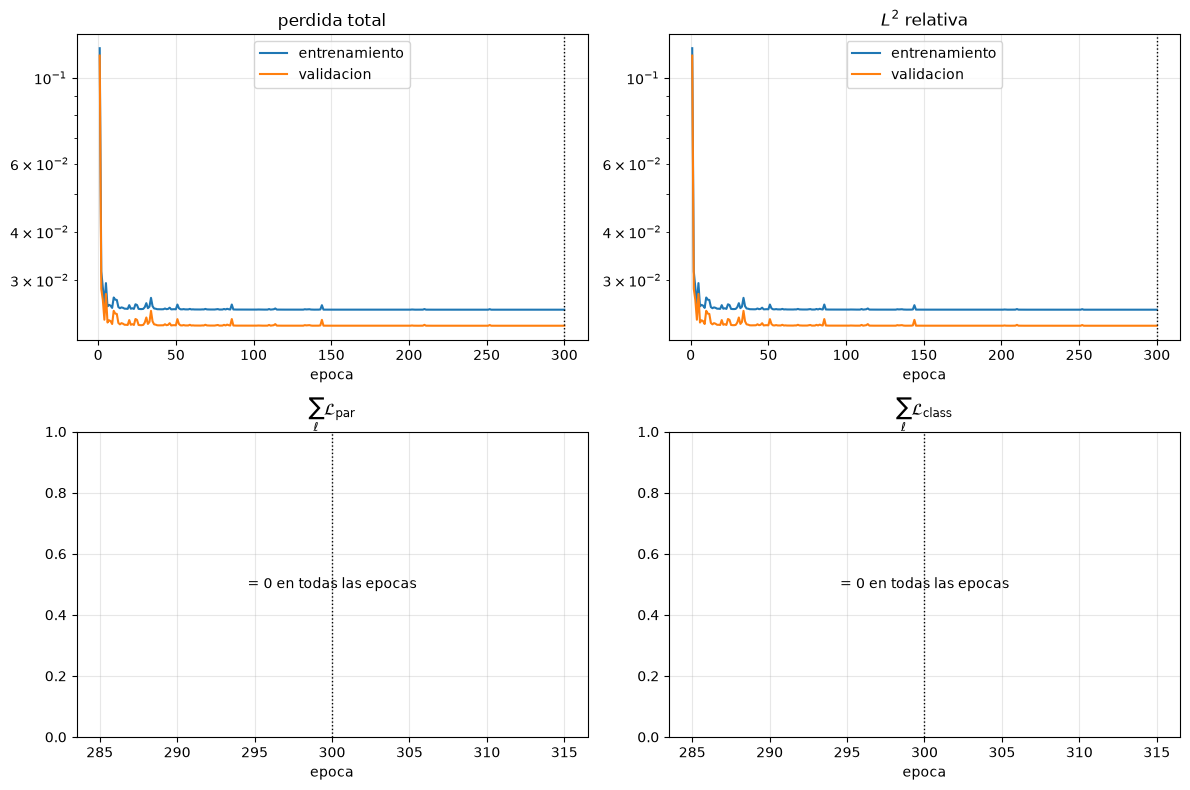

In [8]:
history = result.history
epochs = np.arange(1, len(history["train"]["total"]) + 1)
paneles = [
    ("total", "perdida total"),
    ("rel_l2", r"$L^2$ relativa"),
    ("parabolicity", r"$\sum_\ell \mathcal{L}_{\mathrm{par}}$"),
    ("class", r"$\sum_\ell \mathcal{L}_{\mathrm{class}}$"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (key, titulo) in zip(axes.ravel(), paneles):
    curvas = {"entrenamiento": np.asarray(history["train"][key]),
              "validacion": np.asarray(history["val"][key])}
    if all(np.all(v <= 0) for v in curvas.values()):
        ax.text(0.5, 0.5, "= 0 en todas las epocas", ha="center", va="center", transform=ax.transAxes)
    else:
        for nombre, valores in curvas.items():
            ax.semilogy(epochs, np.where(valores > 0, valores, np.nan), label=nombre)
        ax.legend()
    ax.axvline(result.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
    ax.set_xlabel("epoca")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "perdida.png", dpi=150)
plt.show()

## 6. Prueba

`field_errors` sobre las $20$ $u_0$ de prueba en `TEST_TIMES`: el error relativo $L^2$ en espacio fisico de cada
condicion inicial y tiempo, una matriz `(n_ic, T)`. El promedio global es la metrica comparable con el $<0.01$ del
paper. Los tiempos de `TEST_TIMES` que no estan en `TRAIN_TIMES` (los intermedios y $t=1$) no se vieron al entrenar.

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
error relativo L2 (espacio fisico) = 2.0738e-02  (medio; max 1.1206e-01)


,media,max,en_entrenamiento
t,,,
0.05,0.058091,0.089678,True
0.10,0.052134,0.094487,False
0.15,0.044265,0.110355,True
0.20,0.037681,0.112065,False
0.25,0.032237,0.102872,True
0.30,0.027668,0.088495,False
0.35,0.023830,0.073028,True
0.40,0.020618,0.058671,False
0.45,0.017933,0.046344,True


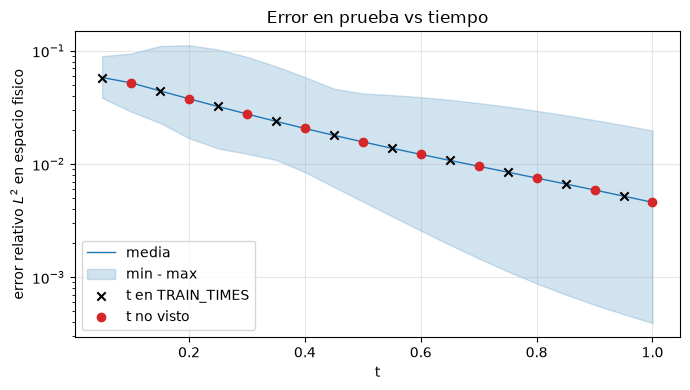

In [9]:
t_train = ds.train.t.numpy()


def error_table(err, t):
    # Media y maximo por tiempo, y el promedio global; err tiene forma (n_ic, T).
    visto = np.isclose(t[:, None], t_train[None]).any(axis=1)
    por_tiempo = pd.DataFrame(
        {"media": err.mean(axis=0), "max": err.max(axis=0), "en_entrenamiento": visto},
        index=pd.Index([f"{x:.2f}" for x in t], name="t"),
    )
    total = pd.DataFrame(
        {"media": [err.mean()], "max": [err.max()], "en_entrenamiento": [None]},
        index=pd.Index(["global"], name="t"),
    )
    return pd.concat([por_tiempo, total])


def error_figure(err, t, titulo, nombre):
    # Media y banda min-max por tiempo; los tiempos no vistos en entrenamiento, con otro marcador.
    visto = np.isclose(t[:, None], t_train[None]).any(axis=1)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.semilogy(t, err.mean(axis=0), "-", color="C0", lw=1, label="media")
    ax.fill_between(t, err.min(axis=0), err.max(axis=0), color="C0", alpha=0.2, label="min - max")
    ax.scatter(t[visto], err.mean(axis=0)[visto], color="k", marker="x", zorder=3,
               label="t en TRAIN_TIMES")
    ax.scatter(t[~visto], err.mean(axis=0)[~visto], color="C3", marker="o", zorder=3,
               label="t no visto")
    ax.set_xlabel("t")
    ax.set_ylabel(r"error relativo $L^2$ en espacio fisico")
    ax.set_title(titulo)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(RESULTS / nombre, dpi=150)
    plt.show()


err_test = field_errors(model, ds.test)        # (n_ic, T)
t_test = ds.test.t.numpy()
print(f"PRUEBA -- {ds.test.n_ic} condiciones iniciales nuevas x {ds.test.n_times} tiempos")
print(f"error relativo L2 (espacio fisico) = {err_test.mean():.4e}  (medio; max {err_test.max():.4e})")

tabla_prueba = error_table(err_test, t_test)
tabla_prueba.to_csv(RESULTS / "prueba.csv")
display(tabla_prueba)

error_figure(err_test, t_test, "Error en prueba vs tiempo", "error_prueba.png")

**Campo.** Primera condicion inicial de prueba: arriba la solucion exacta (continua) y la del PDNO (punteada) en
algunos tiempos de `TEST_TIMES`; abajo el error puntual $u_\theta(t,x)-u(t,x)$.

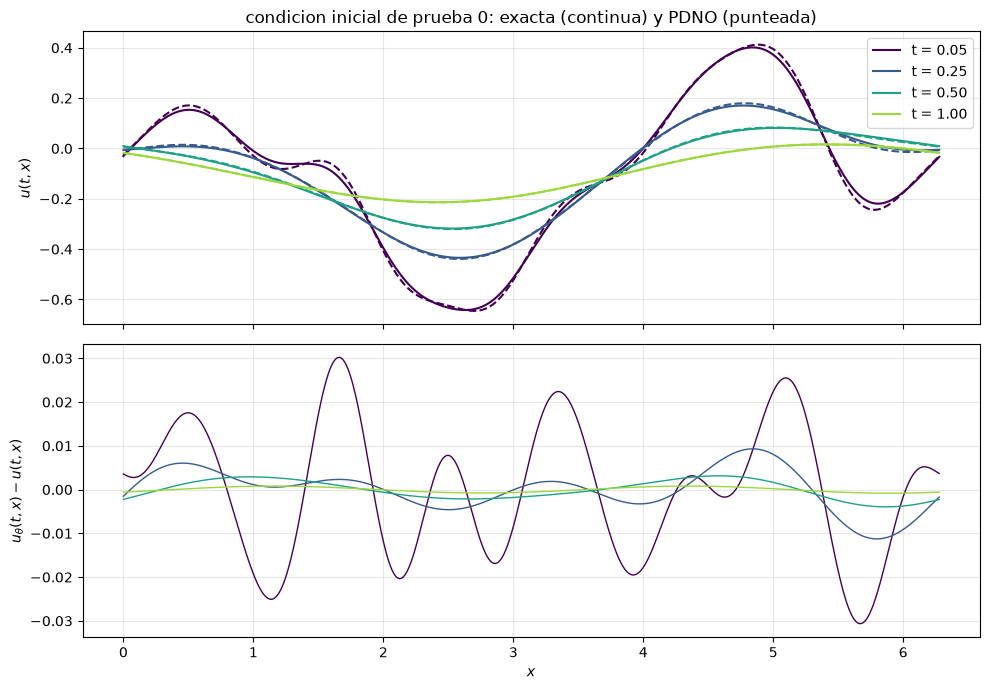

In [10]:
i = 0
idx_t = [0, 4, 9, 19]                                  # t = 0.05, 0.25, 0.5, 1.0
colores = plt.cm.viridis(np.linspace(0, 0.85, len(idx_t)))
t_campo = ds.test.t[idx_t].to(DEVICE, DTYPE)
with torch.no_grad():
    u0_rep = ds.test.u0[i].to(DEVICE, DTYPE).repeat(len(idx_t), 1)
    pred = model(u0_rep, t_campo).cpu().numpy()
exacta = ds.test.u[i, idx_t].numpy()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for j, (t, color) in enumerate(zip(t_campo.cpu().numpy(), colores)):
    axes[0].plot(x, exacta[j], "-", color=color, lw=1.5, label=f"t = {t:.2f}")
    axes[0].plot(x, pred[j], "--", color=color, lw=1.5)
    axes[1].plot(x, pred[j] - exacta[j], "-", color=color, lw=1)
axes[0].set_ylabel(r"$u(t, x)$")
axes[0].set_title(f"condicion inicial de prueba {ds.test.ic[i]}: exacta (continua) y PDNO (punteada)")
axes[0].legend()
axes[1].set_ylabel(r"$u_\theta(t, x) - u(t, x)$")
axes[1].set_xlabel(r"$x$")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "campo.png", dpi=150)
plt.show()

## 7. Simbolo aprendido

El simbolo efectivo $\bar a(k)=\sum_\ell\tau_\ell a_{\text{par}}^{(\ell)}(k)$ (`effective_symbol`) frente a $|k|^2$ en todos los
modos de la malla, $|k|\le512$. La zona sombreada es la ventana de entrenamiento $|k|\le k_{\max}=64$, la de las filas
espectrales de la banda y de los puntos de $\mathcal L_{\text{par}}$ y $\mathcal L_{\text{class}}$. Como $\bar a$ es par, se
dibuja contra $|k|$. A la derecha, $\bar a(k)/\langle k\rangle^m$ esta siempre en la banda $(c,C)$ por construccion.

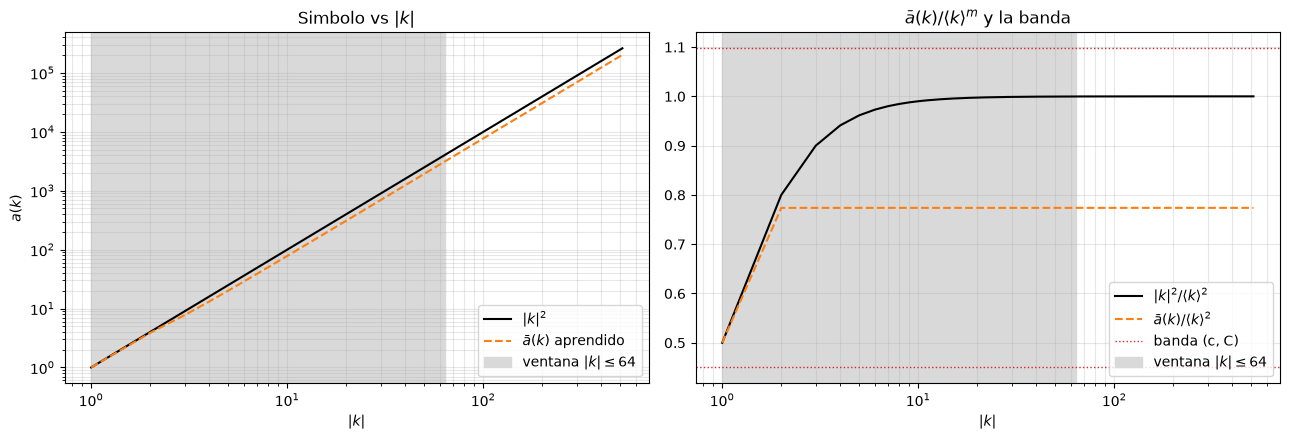

In [11]:
efectivo = EffectiveSymbol(model)
k_sym = k_grid(1, RESOLUTION // 2)
a_eff = np.real(efectivo.evaluate_batch(k_sym))
a_ref = symbol_values(REFERENCE, k_sym)
abs_k = np.abs(k_sym[:, 0])
dentro = abs_k <= k_max
positivo = k_sym[:, 0] > 0
orden = np.argsort(k_sym[positivo, 0])
kk = k_sym[positivo, 0][orden]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(kk, a_ref[positivo][orden], "k-", lw=1.5, label=r"$|k|^2$")
axes[0].loglog(kk, a_eff[positivo][orden], "--", color="C1", lw=1.5, label=r"$\bar a(k)$ aprendido")
axes[0].set_ylabel(r"$a(k)$")
axes[0].set_title(r"Simbolo vs $|k|$")

h_eff = a_eff / (1.0 + k_sym[:, 0] ** 2) ** (M / 2)
h_ref = a_ref / (1.0 + k_sym[:, 0] ** 2) ** (M / 2)
axes[1].semilogx(kk, h_ref[positivo][orden], "k-", lw=1.5, label=r"$|k|^2 / \langle k\rangle^2$")
axes[1].semilogx(kk, h_eff[positivo][orden], "--", color="C1", lw=1.5, label=r"$\bar a(k) / \langle k\rangle^2$")
axes[1].axhline(bounds.c, color="C3", ls=":", lw=1, label="banda (c, C)")
axes[1].axhline(bounds.C, color="C3", ls=":", lw=1)
axes[1].set_title(r"$\bar a(k) / \langle k\rangle^m$ y la banda")
for ax in axes:
    ax.axvspan(1, k_max, color="0.85", zorder=0, label=rf"ventana $|k| \leq {k_max}$")
    ax.set_xlabel(r"$|k|$")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.tight_layout()
fig.savefig(RESULTS / "simbolo.png", dpi=150)
plt.show()

**Error del simbolo.** $|\bar a(k)-|k|^2|/|k|^2$ en cada $|k|$ ($k=0$ se omite: ahi ambos valen $0$), dentro y fuera
de la ventana. Fuera de ella el multiplicador $e^{-t|k|^2}$ es practicamente $0$ para casi todos los $t$, asi que los
datos casi no informan sobre $\bar a$ y solo la banda lo restringe.

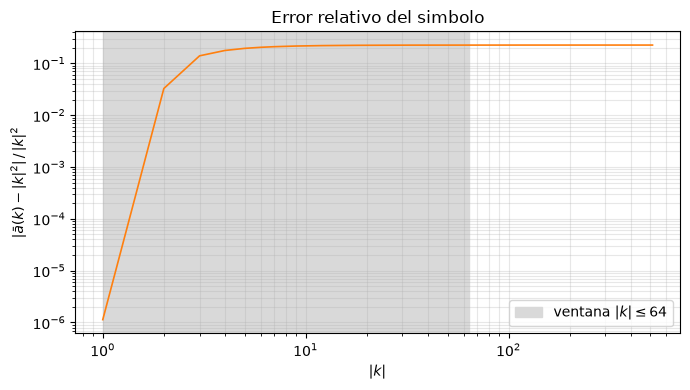

,dentro (|k| <= 64),fuera (|k| > 64)
n,129.000000,8.960000e+02
mse,176668.181914,8.078938e+08
rmse,420.319143,2.842347e+04
mae,312.970357,2.261434e+04
max_error,925.935249,5.930860e+04
rel_l2,0.225937,2.262424e-01
error_relativo_medio,0.215103,2.262239e-01
error_relativo_max,0.226058,2.262444e-01


In [12]:
rel = relative_symbol_error(a_eff, a_ref)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(kk, rel[positivo][orden], "-", color="C1", lw=1.2)
ax.axvspan(1, k_max, color="0.85", zorder=0, label=rf"ventana $|k| \leq {k_max}$")
ax.set_xlabel(r"$|k|$")
ax.set_ylabel(r"$|\bar a(k) - |k|^2| \,/\, |k|^2$")
ax.set_title("Error relativo del simbolo")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig(RESULTS / "error_simbolo.png", dpi=150)
plt.show()

no_cero = abs_k > 0
metricas = {}
for nombre, region in (("dentro (|k| <= %d)" % k_max, dentro), ("fuera (|k| > %d)" % k_max, ~dentro)):
    reporte = symbol_report(efectivo, REFERENCE, k_sym[region])
    reporte["error_relativo_medio"] = float(rel[region & no_cero].mean())
    reporte["error_relativo_max"] = float(rel[region & no_cero].max())
    metricas[nombre] = reporte
metricas_simbolo = pd.DataFrame(metricas)
metricas_simbolo.to_csv(RESULTS / "metricas_simbolo.csv")
display(metricas_simbolo)

**Multiplicador.** $e^{-t\bar a(k)}$ aprendido (punteado) frente a $e^{-t|k|^2}$ (continuo) para algunos $t$, sobre
$0\le k\le k_{\max}$, como la Figura 3 del paper; abajo su diferencia absoluta. El multiplicador solo es informativo en
la franja donde no es ni $1$ ni $0$: ahi es donde los datos fijan $\bar a(k)$.

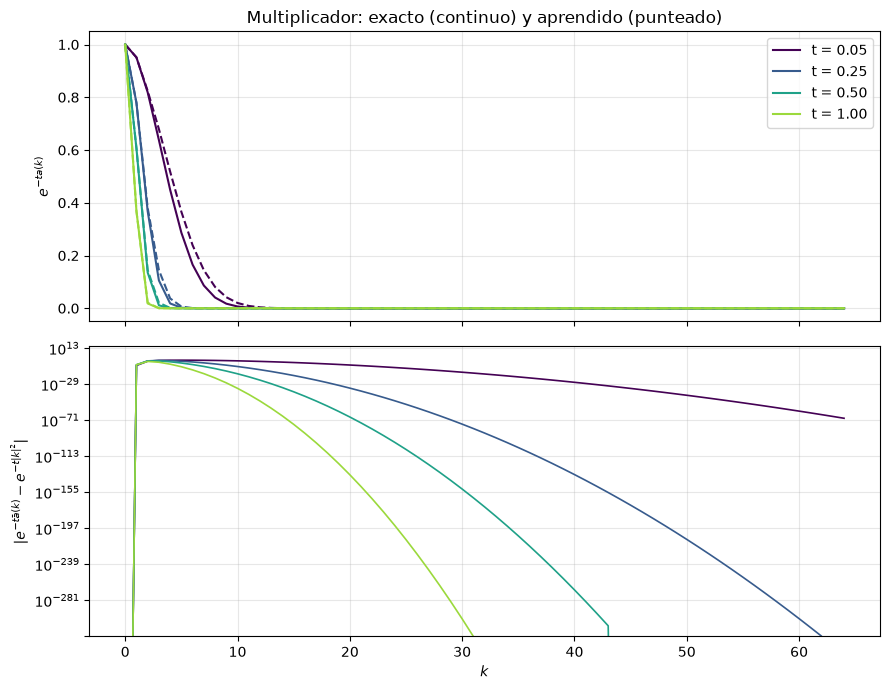

In [13]:
t_mult = [0.05, 0.25, 0.5, 1.0]
colores = plt.cm.viridis(np.linspace(0, 0.85, len(t_mult)))
k_mult = np.arange(0, k_max + 1)
sel = np.searchsorted(k_sym[:, 0], k_mult)              # k_sym esta ordenado de -512 a 512

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for t, color in zip(t_mult, colores):
    exacto = np.exp(-t * a_ref[sel])
    aprendido = np.exp(-t * a_eff[sel])
    axes[0].plot(k_mult, exacto, "-", color=color, lw=1.5, label=f"t = {t:.2f}")
    axes[0].plot(k_mult, aprendido, "--", color=color, lw=1.5)
    axes[1].semilogy(k_mult, np.abs(aprendido - exacto), "-", color=color, lw=1.2)
axes[0].set_ylabel(r"$e^{-t a(k)}$")
axes[0].set_title("Multiplicador: exacto (continuo) y aprendido (punteado)")
axes[0].legend()
axes[1].set_ylabel(r"$|e^{-t \bar a(k)} - e^{-t |k|^2}|$")
axes[1].set_xlabel(r"$k$")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig(RESULTS / "multiplicador.png", dpi=150)
plt.show()

## 8. Certificacion

**Parabolicidad (Def. 2.3).** `ParabolicityVerifier` sobre el simbolo de cada capa y sobre el efectivo, con la rejilla
de certificacion de `GRFExperiment`: $k$ en $|k|\le K$ para $K\in\{k_{\max},2k_{\max},3k_{\max}\}$ y `CERT_LAM`
($|\lambda|$ log-espaciado en $[10^{-2},10^3]$, $25$ angulos en $[-\pi/2,\pi/2]$). El peor ratio es
$\hat\kappa/\kappa$, con $\kappa=$ `theoretical_kappa()`; se cumple si es $\le1$.

**Clase $S^{m,\rho}$ (Def. 2.1).** `SymbolClassVerifier` en ventanas crecientes, como en 02. Es evidencia en una ventana
finita, no una prueba sobre todo $\mathbb Z^n$.

In [14]:
kappa = model.theoretical_kappa(OMEGA)
cert_k_max = 3 * k_max
simbolos = {f"capa {l}": s for l, s in enumerate(model.symbols)}
simbolos["efectivo"] = efectivo

filas = []
for nombre, simbolo in simbolos.items():
    verifier = ParabolicityVerifier(simbolo)
    for window in (k_max, 2 * k_max, cert_k_max):
        k_values = k_grid(1, window)
        ratio = verifier.estimate_kappa_batch(k_values, CERT_LAM, omega=OMEGA) / kappa
        filas.append({
            "simbolo": nombre, "K": window, "region": "dentro" if window <= k_max else "fuera",
            "puntos": len(k_values) * len(CERT_LAM), "max_ratio": ratio, "satisfecha": ratio <= 1.0,
        })
certificacion = pd.DataFrame(filas)
certificacion.to_csv(RESULTS / "certificacion.csv", index=False)
print(f"kappa usada = {kappa:.4f}")
display(certificacion)

kappa usada = 3.1427


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.711211,True
1,capa 0,128,fuera,160625,0.711211,True
2,capa 0,192,fuera,240625,0.711211,True
3,efectivo,64,dentro,80625,0.711211,True
4,efectivo,128,fuera,160625,0.711211,True
5,efectivo,192,fuera,240625,0.711211,True


In [15]:
class_k_maxs = (4, 8, 12, 2 * k_max)
filas = []
for nombre, simbolo in simbolos.items():
    for r in SymbolClassVerifier(simbolo).check(k_maxs=class_k_maxs):
        filas.append({
            "simbolo": nombre,
            "alpha": str(r.alpha),
            "|alpha|": r.order,
            **{f"C_hat({K})": r.c_hat[K] for K in class_k_maxs},
            f"crecim.({class_k_maxs[-2]}->{class_k_maxs[-1]})": r.growth,
            "pendiente": r.slope,
            "m-|alpha|": r.slope_theoretical,
            "estable": r.stable,
            "consistente": r.consistent,
        })
clase = pd.DataFrame(filas)
clase.to_csv(RESULTS / "clase.csv", index=False)
display(clase)

for nombre, grupo in clase.groupby("simbolo", sort=False):
    print(f"{nombre}: consistentes {int(grupo['consistente'].sum())} de {len(grupo)} multiindices")
print(f"ventana explorada: |k| <= {class_k_maxs[-1]} (evidencia, no prueba sobre todo Z^n)")
print("pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta")

,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.773751,0.773752,0.773753,0.773753,1.0,2.000000e+00,2.0,True,True
1,capa 0,"(1,)",1,2.028466,2.028466,2.028466,2.028466,1.0,9.946429e-01,1.0,True,True
2,capa 0,"(2,)",2,2.000002,2.000002,2.000002,2.000002,1.0,2.219648e-11,0.0,True,True
3,efectivo,"(0,)",0,0.773751,0.773752,0.773753,0.773753,1.0,2.000000e+00,2.0,True,True
4,efectivo,"(1,)",1,2.028466,2.028466,2.028466,2.028466,1.0,9.946429e-01,1.0,True,True
5,efectivo,"(2,)",2,2.000002,2.000002,2.000002,2.000002,1.0,2.219648e-11,0.0,True,True


capa 0: consistentes 3 de 3 multiindices
efectivo: consistentes 3 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


## 9. Extrapolacion temporal

Solo si `EXTRAPOLATION_TIMES` no es `None`: las $u_0$ de prueba en tiempos $t>0.95$, fuera de `TRAIN_TIMES`. Lo mismo que
en la seccion 6; solo se reporta, no interviene en el entrenamiento ni en la seleccion.

In [16]:
if ds.extrapolation is None:
    print("EXTRAPOLATION_TIMES = None: seccion omitida")
else:
    err_ext = field_errors(model, ds.extrapolation)    # (n_ic, T)
    t_ext = ds.extrapolation.t.numpy()
    print(f"EXTRAPOLACION -- {ds.extrapolation.n_ic} condiciones iniciales x {ds.extrapolation.n_times} tiempos")
    print(f"error relativo L2 (espacio fisico) = {err_ext.mean():.4e}  (medio; max {err_ext.max():.4e})")

    tabla_ext = error_table(err_ext, t_ext)
    tabla_ext.to_csv(RESULTS / "extrapolacion.csv")
    display(tabla_ext)

    error_figure(err_ext, t_ext, "Error en extrapolacion temporal vs tiempo", "error_extrapolacion.png")

EXTRAPOLATION_TIMES = None: seccion omitida


## 10. Modelo guardado

`save_operator_model` guarda en `results/06_pdno_calor_1d/modelo.pt` los pesos, la `PDNOConfig` (con $(c,C)$ y $m$), la
`OperatorTrainingConfig`, las $C_\alpha$ usadas y lo necesario para regenerar los datos. Para reconstruirlo sin este
notebook:

```python
from parabolic_symbol.learning.operator_training import load_operator_datasets, load_operator_model
model = load_operator_model("results/06_pdno_calor_1d/modelo.pt")
ds = load_operator_datasets("results/06_pdno_calor_1d/modelo.pt")   # misma semilla, mismos datos
```

La ultima celda recarga el modelo y comprueba que da el mismo error de prueba.

In [17]:
save_operator_model(
    RESULTS / "modelo.pt", model, reference=REFERENCE, resolution=RESOLUTION, k_cap=K_CAP,
    config=TRAIN_CONFIG, result=result, seed=SEED, val_fraction=VAL_FRACTION,
    extrapolation_times=EXTRAPOLATION_TIMES, delta=DELTA, estimate_tol=ESTIMATE_TOL,
)

modelo guardado en ../results/06_pdno_calor_1d/modelo.pt


PosixPath('../results/06_pdno_calor_1d/modelo.pt')

In [18]:
cargado = load_operator_model(RESULTS / "modelo.pt", device=DEVICE)
err_cargado = field_errors(cargado, ds.test)
print(f"error de prueba (cargado) = {err_cargado.mean():.6e}  |  (entrenado) = {err_test.mean():.6e}")
print(f"identicos: {np.array_equal(err_cargado, err_test)}")

error de prueba (cargado) = 2.073776e-02  |  (entrenado) = 2.073776e-02
identicos: True
